In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [78]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

#initial exploration
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [36]:
#Number of rows and columns
df.shape

(2443651, 9)

In [37]:
#Datatypes of each columns
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [7]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [8]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [ ]:
##Part 1: Understanding Product Categories
##Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

##Frequency Tables:

##Generate a frequency table for the product category.
##Which are the top 5 most listed product categories?

##Visualizations:

##Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
##For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


In [41]:
frequency_table = df["category"].value_counts()
frequency_table
top5 = frequency_table.head(5).reset_index()
top5.columns = ["category","frequency"]
top5

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


In [ ]:
The top 5 most listed product categories are : 
Sports & Outdoor, Beauty, Handmade Clothing/Shoes/Acessories, Bath & Body, Birthday Gift.

C:\Users\jtrin\AppData\Local\Temp\ipykernel_22960\3826302941.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data= top5, x=top5["frequency"], y=top5["category"], palette="Set3")


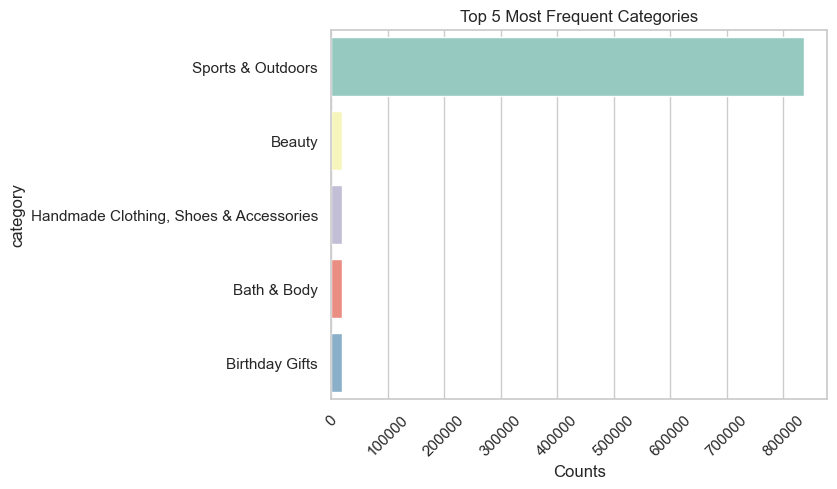

In [42]:
sns.barplot(data= top5, x=top5["frequency"], y=top5["category"], palette="Set3")
sns.set(style="whitegrid") #background

plt.title("Top 5 Most Frequent Categories")
plt.xticks(rotation=45) #Change the rotation of label on x, for y, it would be the same just yticks
plt.yticks(rotation=0)
plt.xlabel("Counts")
plt.show()

In [ ]:
We observe that Sport & Outdoors is dominating the others categories 

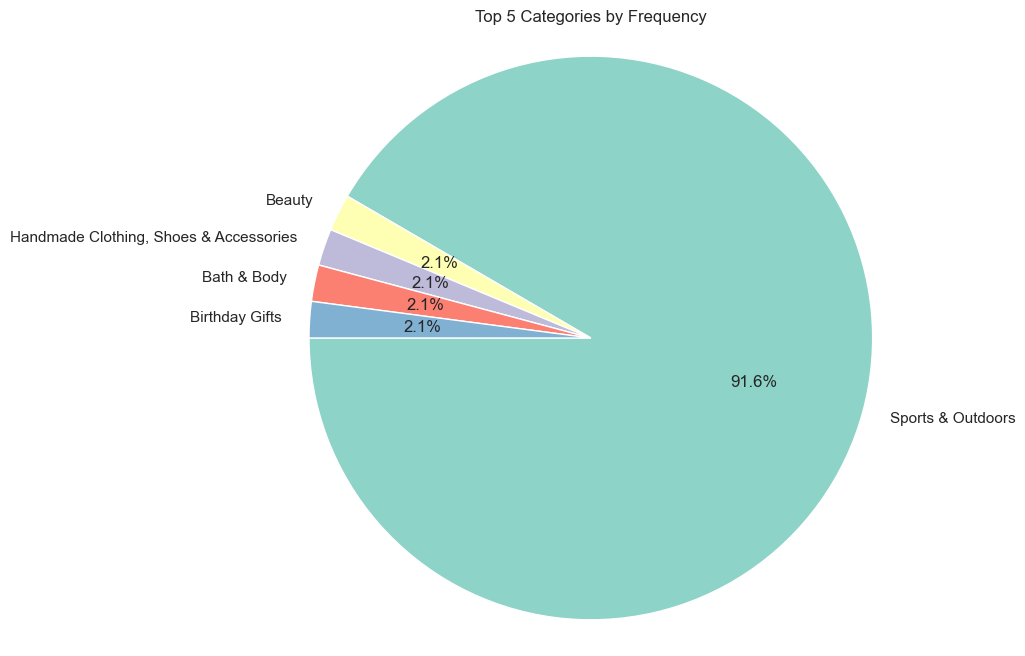

In [45]:
labels = top5['category']
frequency = top5['frequency']

plt.figure(figsize=(8, 8))
plt.pie(frequency, labels=labels, autopct='%1.1f%%', startangle=180, colors=sns.color_palette("Set3"))
plt.title("Top 5 Categories by Frequency")
plt.axis('equal')
plt.show()

In [ ]:
##Part 2: Delving into Product Pricing
#Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

#Measures of Centrality:

#Calculate the mean, median, and mode for the price of products.
#What's the average price point of products listed? How does this compare with the most common price point (mode)?

#Measures of Dispersion:

#Determine the variance, standard deviation, range, and interquartile range for product price.
#How varied are the product prices? Are there any indicators of a significant spread in prices?

#Visualizations:

#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
#Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.


In [47]:
df["price"].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [56]:
mean_price = df["price"].mean()

In [54]:
median_price = df["price"].median()

In [53]:
mode_price = df["price"].mode()

In [52]:
range_price = df["price"].max() - df["price"].min()

In [55]:
var_price = df["price"].var()

In [72]:
interquartile_price = df["price"].quantile(0.75) - df["price"].quantile(0.25)

In [73]:
std_price = df["price"].std()

In [74]:
#Calculate the mean, median, and mode for the price of products.
#What's the average price point of products listed? How does this compare with the most common price point (mode)?
print (f" Mean : {mean_price} \n"
        f" Median : {median_price}\n"
        f" Mode : {mode_price}\n"
        f" Range : {range_price}\n"
        f" Var : {var_price}\n"
        f" Standard deviation : {std_price}\n"
        f" Interquartile : {interquartile_price}\n")

 Mean : 89.24380943923663 
 Median : 19.09
 Mode : 0    9.99
Name: price, dtype: float64
 Range : 100000.0
 Var : 119445.48532256528
 Standard deviation : 345.60886175352226
 Interquartile : 36.0



In [ ]:
The average price of 89.24£ is way over the most common price which is 9.99£ and 0£. This result suggest they are probably extreme high prices that
influence the average.

In [ ]:
#Determine the variance, standard deviation, range, and interquartile range for product price.
#How varied are the product prices? Are there any indicators of a significant spread in prices?

We can observe that the variance (119 445) and the standard deviation (345) are high which means a lot of diverse prices. As for the spread in prices, 
we can observe that the range (100 000) and the variance (119 445) are very high that means a large spread in prices and so products can be really 
cheap but also very expensive.

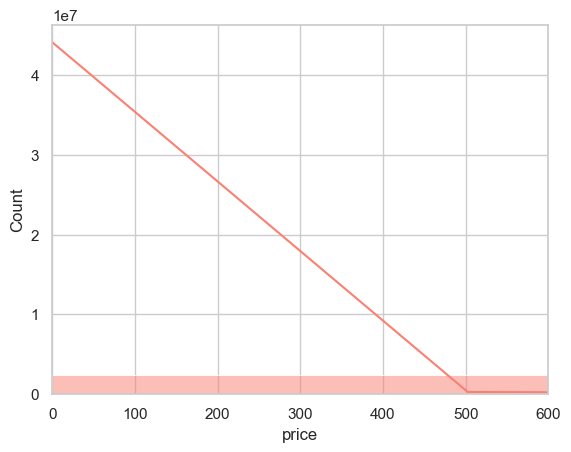

In [89]:
#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these 
#diagrams, think why this is, and explain how it could be solved..
#Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.
fig,axes = plt.subplots()
sns.histplot(df["price"], bins=60, color = "salmon", kde= True)
plt.xlim(0, 600)
plt.show()

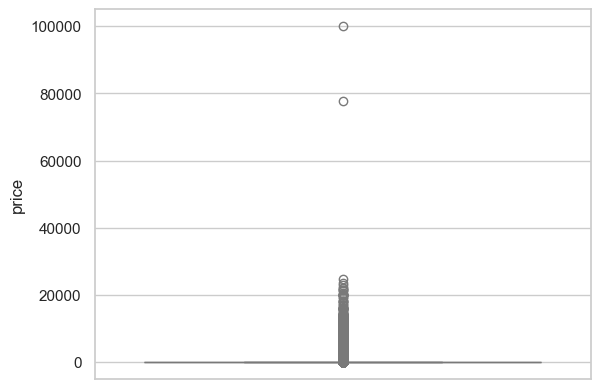

In [86]:
sns.boxplot(data = df['price'], color="lightblue")
plt.show()

In [ ]:
It's hard to see any in details because the prices are too spread. The best way would be to focus on a price's range, for example between 0 and 5000.

In [ ]:
#Part 3: Unpacking Product Ratings
#Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

#Measures of Centrality:

#Calculate the mean, median, and mode for the rating of products.
#How do customers generally rate products? Is there a common trend?

#Measures of Dispersion:

#Determine the variance, standard deviation, and interquartile range for product rating.
#Are the ratings consistent, or is there a wide variation in customer feedback?
#Shape of the Distribution:

#Calculate the skewness and kurtosis for the rating column.
#Are the ratings normally distributed, or do they lean towards higher or lower values?
##Visualizations:

#Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


In [59]:
mean_rating = df["stars"].mean()

In [60]:
median_rating = df["stars"].median()

In [61]:
mode_rating = df["stars"].mode()

In [70]:
print(f" Mean : {mean_rating} \n"
f"Median : {median_rating} \n"
f"Mode : {mode_rating}") 

 Mean : 2.152836472966065 
Median : 0.0 
Mode : 0    0.0
Name: stars, dtype: float64


In [ ]:
#How do customers generally rate products? Is there a common trend?
The average shows a rating around 2 but it's probably influenced by the higher rating because we can observe the median where we can observe a median of
0. We can also prove that a rating of 0 is a common trend because the mode (which is the most frequent value) is 0.

In [91]:
var_rating = df["stars"].var()

In [92]:
interquartile_rating = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

In [93]:
std_rating = df["stars"].std()

In [94]:
print(f" Variance : {var_rating} \n"
f"Interquartile : {interquartile_rating} \n"
f"Standard deviation : {std_rating}") 

 Variance : 4.81743402976196 
Interquartile : 4.4 
Standard deviation : 2.1948653785054697


In [ ]:
#Are the ratings consistent, or is there a wide variation in customer feedback?
Even though the value of the variance, interquartile and standard deviation are small, because the rating is out of 5 stars, I would say it's a wide range 
because it takes all the range.

In [95]:
#Calculate the skewness and kurtosis for the rating column.
#Are the ratings normally distributed, or do they lean towards higher or lower values?
skewness_rating = df['stars'].skew() 

kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(0.08120735761080985, -1.9260061280432985)

In [ ]:
#Are the ratings normally distributed, or do they lean towards higher or lower values?
The skewness is close to 0 so it means that the rating are symetric. The kurtosis is negative which means is spread evenly.

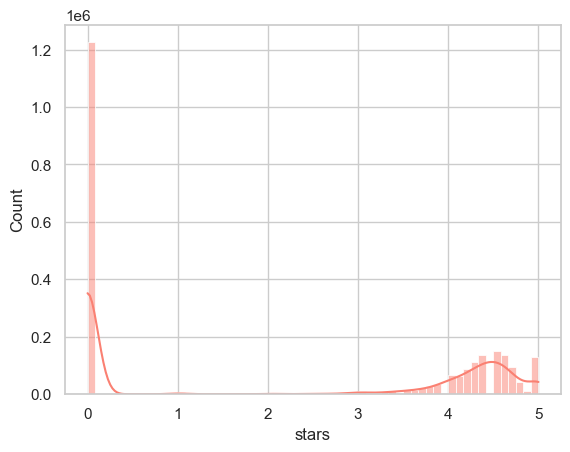

In [96]:
#Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
fig,axes = plt.subplots()
sns.histplot(df["stars"], bins=60, color = "salmon", kde= True)
plt.show()

In [ ]:
The most common it's 0 as a rating.